# Lab 4 ANN for forest and urban patches

For this exercise I've used Sentinel-2 images to classify patches as forest or urban. In Lab 3 I used the red and near-infrared bands to classify single pixels. Here I take the mean of each band over a whole patch

The ANN takes those two means and returns the probabilty that the patch is urban. If the probability is above 0.5 I tag it as urban (1), otherwise I tag it as forest (0)

## Training data

I used one Sentinel-2 L2A scene from summer 2021 for each city and its surroudings. I cropped a 24 by 24 km area from each scene and divided it into a grid of 200 by 200 pixel patches. At 10 m per pixel, each patch covers 2 by 2 km

I aligned ESA WorldCover 2021 to the Sentinel-2 grid using nearest neighbour resampling. I labelled a patch forest if at least 55 percent of it was tree cover and urban if at least 55 percent was built-up

I kept patches with at least 95 percent valid pixels. I counted a pixel as valid if both band values were positive and Sentinel-2 marked it as vegetation, non-vegetated land or water. I used the original red and NIR values of those pixels for the means and only used WorldCover for the labels

I used Krakow, Katowice, Warsaw and Wroclaw for training, Lodz and Lublin for validation, and Poznan, Gdansk and Szczecin for testing. All patches from a city stay in the same set

The CSV has one row per patch with the scene ID and the upper left pixel. I made it with `uv run python lab_4/prepare_patches.py` from the repo root. The notebook uses the saved CSV

In [1]:
import csv
from collections import Counter
from pathlib import Path
import sys

from IPython.display import Markdown, display
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score, recall_score,
)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

lab_dir = Path("lab_4") if Path("lab_4/patches.csv").is_file() else Path(".")
sys.path.insert(0, str(lab_dir.resolve().parent / "lab_3"))
from bayes_classifier import bayes_predict, fit_bayes

with (lab_dir / "patches.csv").open(newline="", encoding="utf-8") as file:
    patches = list(csv.DictReader(file))
features = ["mean_red", "mean_nir"]
class_names = ["forest", "urban"]
seed = 2026

def show_table(headers, rows):
    lines = [headers, ["---"] * len(headers), *rows]
    display(Markdown("\n".join("| " + " | ".join(map(str, row)) + " |" for row in lines)))


counts = Counter((row["split"], row["region"], row["label"]) for row in patches)
regions = dict.fromkeys((row["split"], row["region"]) for row in patches)
show_table(["Split", "Region", "Forest", "Urban"], [
    [split, region, counts[split, region, "forest"], counts[split, region, "urban"]]
    for split, region in regions
])

| Split | Region | Forest | Urban |
| --- | --- | --- | --- |
| train | Krakow | 32 | 6 |
| train | Katowice | 11 | 0 |
| train | Warsaw | 35 | 19 |
| train | Wroclaw | 9 | 1 |
| validation | Lodz | 31 | 3 |
| validation | Lublin | 12 | 3 |
| test | Poznan | 6 | 2 |
| test | Gdansk | 29 | 7 |
| test | Szczecin | 49 | 5 |

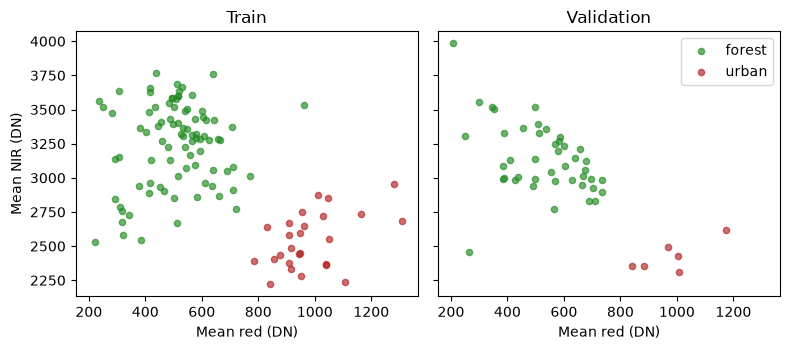

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.6), sharex=True, sharey=True)
for ax, split in zip(axes, ("train", "validation")):
    for label, color in zip(class_names, ("forestgreen", "firebrick")):
        group = [row for row in patches if row["split"] == split and row["label"] == label]
        red, nir = np.array([[float(row[band]) for band in features] for row in group]).T
        ax.scatter(red, nir, label=label, s=20, alpha=0.65, color=color)
    ax.set(title=split.capitalize(), xlabel="Mean red (DN)")
axes[0].set_ylabel("Mean NIR (DN)")
axes[-1].legend()
plt.tight_layout()
plt.show()

## ANN setup

I started with two inputs, two ReLU neurons in one hidden layer and one sigmoid output. There are nine weights and biases to fit. I used binary log loss, so a confident wrong prediction adds more to the loss

I went with scikit-learn because it was already in the lab environment. MLPClassifier gave me the two-input network I needed and let me switch optimisers by changing one setting, so I didn't have to add Keras for this lab

I tried wider layers, a second hidden layer and three optimisers, Adam, SGD and L-BFGS. I used the same patches for all six runs and scaled the inputs using the training set. For each run I averaged the validation recall for forest and urban. If two runs had the same score I picked the one with fewer parameters

In [3]:
def split_data(split):
    rows = [row for row in patches if row["split"] == split]
    X = np.array([[float(row[band]) for band in features] for row in rows])
    y = np.array([class_names.index(row["label"]) for row in rows])
    return X, y


X_train, y_train = split_data("train")
X_val, y_val = split_data("validation")
X_test, y_test = split_data("test")

runs = [
    ("Small ANN", (2,), "adam"),
    ("8 neurons", (8,), "adam"),
    ("32 neurons", (32,), "adam"),
    ("Two hidden layers", (8, 4), "adam"),
    ("8 neurons + SGD", (8,), "sgd"),
    ("8 neurons + L-BFGS", (8,), "lbfgs"),
]

models = {}
scores = []
for name, hidden, solver in runs:
    ann = MLPClassifier(
        hidden_layer_sizes=hidden, activation="relu", solver=solver,
        learning_rate_init=0.01, max_iter=3000, random_state=seed, n_iter_no_change=30,
    )
    model = make_pipeline(StandardScaler(), ann).fit(X_train, y_train)
    models[name] = model
    validation_predictions = model.predict(X_val)
    scores.append({
        "name": name,
        "hidden": hidden,
        "solver": solver,
        "parameters": sum(array.size for array in ann.coefs_ + ann.intercepts_),
        "iterations": ann.n_iter_,
        "train_accuracy": model.score(X_train, y_train),
        "val_accuracy": accuracy_score(y_val, validation_predictions),
        "val_balanced": balanced_accuracy_score(y_val, validation_predictions),
    })

show_table(
    ["Run", "Hidden layers", "Optimiser", "Parameters", "Iterations",
     "Train accuracy", "Val. accuracy", "Val. balanced accuracy"],
    [
        [row["name"], row["hidden"], row["solver"], row["parameters"], row["iterations"],
         f"{row['train_accuracy']:.1%}", f"{row['val_accuracy']:.1%}", f"{row['val_balanced']:.1%}"]
        for row in scores
    ],
)
best_run = min(scores, key=lambda row: (-row["val_balanced"], row["parameters"]))["name"]
print(f"Selected ANN: {best_run}")

| Run | Hidden layers | Optimiser | Parameters | Iterations | Train accuracy | Val. accuracy | Val. balanced accuracy |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Small ANN | (2,) | adam | 9 | 408 | 100.0% | 100.0% | 100.0% |
| 8 neurons | (8,) | adam | 33 | 220 | 100.0% | 100.0% | 100.0% |
| 32 neurons | (32,) | adam | 129 | 155 | 100.0% | 100.0% | 100.0% |
| Two hidden layers | (8, 4) | adam | 65 | 443 | 100.0% | 100.0% | 100.0% |
| 8 neurons + SGD | (8,) | sgd | 33 | 256 | 100.0% | 100.0% | 100.0% |
| 8 neurons + L-BFGS | (8,) | lbfgs | 33 | 12 | 100.0% | 100.0% | 100.0% |

Selected ANN: Small ANN


## Test patches

I compared the selected ANN with the Gaussian Bayes classifier from Lab 3. I fitted one Gaussian to each class and used equal priors. Both models used the same red and NIR means, and I kept the test patches aside until I'd picked the ANN

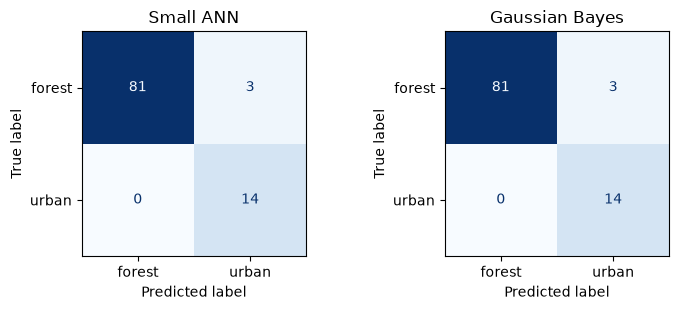

| Model | Accuracy | Balanced accuracy | Forest recall | Urban recall |
| --- | --- | --- | --- | --- |
| Small ANN | 96.9% | 98.2% | 96.4% | 100.0% |
| Gaussian Bayes | 96.9% | 98.2% | 96.4% | 100.0% |

In [4]:
ann = models[best_run]
means, covariances = fit_bayes(X_train, y_train)
test_predictions = {
    best_run: ann.predict(X_test),
    "Gaussian Bayes": bayes_predict(X_test, means, covariances, [0.5, 0.5]),
}

test_scores = []
fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.2))
for ax, (name, prediction) in zip(axes, test_predictions.items()):
    forest_recall, urban_recall = recall_score(y_test, prediction, average=None, labels=[0, 1])
    test_scores.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, prediction),
        "Balanced accuracy": balanced_accuracy_score(y_test, prediction),
        "Forest recall": forest_recall,
        "Urban recall": urban_recall,
    })
    ConfusionMatrixDisplay.from_predictions(
        y_test, prediction, labels=[0, 1], display_labels=class_names,
        colorbar=False, cmap="Blues", ax=ax,
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

metrics = ["Accuracy", "Balanced accuracy", "Forest recall", "Urban recall"]
show_table(
    ["Model", *metrics],
    [[row["Model"], *(f"{row[metric]:.1%}" for metric in metrics)] for row in test_scores],
)

In [5]:
# Take one held-out patch and predict its tag from the two band means
example = X_test[:1]
predicted = class_names[ann.predict(example)[0]]
probability = ann.predict_proba(example)[0, 1]
reference = next(row for row in patches if row["split"] == "test")
print(f"{reference['region']}, scene {reference['scene_id']}, row {reference['row']}, col {reference['col']}")
print(f"Urban probability: {probability:.3f}")
print(f"Predicted tag: {predicted} | WorldCover tag: {reference['label']}")

Poznan, scene S2B_33UXU_20210614_0_L2A, row 8010, col 2494
Urban probability: 0.000
Predicted tag: forest | WorldCover tag: forest


## Results

All six runs got the 49 validation patches right. Only six of those patches were urban. Adding neurons or another layer made no diference to the score, so I kept the one with two neurons. L-BFGS took the fewest iterations, though each iteration does different work from a pass of Adam or SGD

The ANN and Bayes each got 95 of the 98 test patches right. That gives 96.9 percent accuracy and 98.2 percent balanced accuracy. Both models caught all 14 urban patches and tagged three forest patches as urban

I'd use Bayes for these two features. It gives the same score here and there is no hidden layer size or optimiser to choose. The labels come from WorldCover and all the scenes are from summer 2021, so I'd want to try more urban patches and a different season

## Sources

I used modified Copernicus Sentinel data from 2021 through [Element 84 Earth Search](https://github.com/Element84/earth-search/blob/main/docs/collections/sentinel-2-l2a.md)

The labels come from the ESA WorldCover project 2021. It contains modified Copernicus Sentinel data from 2021 processed by the ESA WorldCover consortium. [ESA WorldCover 10 m 2021 v200](https://doi.org/10.5281/zenodo.7254221)

[Sentinel-2 band and SCL reference](https://docs.sentinel-hub.com/api/latest/data/sentinel-2-l2a/) and [scikit-learn MLPClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html)